# WP12 · Kullanıcı PDF'leri için veri sözleşmesi hazırlığı

**Gerçek PDF sağlanmadı.** Bu notebook gerçek belge çıkarımı değildir;boş envanter veuygulama ön hazırlığını gösterir. Kullanıcı prospektüs PDF'lerini kendisi sağlayacak. Otomatik arama/indirme,PDF açma,Ollama/LLM kurulumu veya eğitim yoktur.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/preparation_v1'
F=ROOT/'reports/figures/WP12/preparation_v1';F.mkdir(parents=True,exist_ok=True)
readiness=json.loads((Q/'readiness.json').read_text(encoding='utf-8'))
display(pd.DataFrame([readiness]).T.rename(columns={0:'gerçek_durum'}))
inventory=pd.read_csv(Q/'document_inventory.csv');display(inventory)
print('Gerçek belge envanteri satırı:',len(inventory))


Gerçek belge envanteri satırı: 0


,gerçek_durum
state,AWAITING_USER_PDFS
user_provided_PDFs,0
documents_registered,0
extraction_runs,0
pages_extracted,0
quotes_extracted,0
real_document_validation,NOT_RUN_NO_USER_PDF
contract_implemented,True
PDF_parser_implemented,False
Ollama_installed_by_this_task,False


,document_id,raw_sha256,raw_size_bytes,page_count,declared_version,receipt_count,status


**Yorum:**0 satır “bilgisayarda PDF yok” anlamına gelmez;bu çalışmaya kullanıcı PDF'si verilmediğini gösterir. Sahte prospektüs veya örnek tıbbi içerik gerçek veri gibi eklenmedi. Sayfa vealıntı sayısı da0'dır.

## 1. Belge kimliği ile alıntı arasındaki bağ

In [2]:

fields=pd.read_csv(Q/'contract_field_dictionary.csv');display(fields)
from wp12_document_contract import validate_bundle
bundle=json.loads((Q/'empty_document_bundle.json').read_text(encoding='utf-8'))
display(pd.DataFrame([validate_bundle(bundle)]))


,entity,field,required,shape
0,receipt,receipt_id,True,"{""type"": ""string"", ""minLength"": 1}"
1,receipt,source_kind,True,"{""const"": ""user_provided_pdf""}"
2,receipt,receipt_kind,True,"{""enum"": [""user_attachment"", ""explicit_user_file""]}"
3,receipt,reference,True,"{""type"": ""string"", ""minLength"": 1}"
4,receipt,original_filename,True,"{""type"": ""string"", ""minLength"": 1}"
5,receipt,supplied_at,True,"{""type"": ""string"", ""minLength"": 1}"
6,document,document_id,True,"{""type"": ""string"", ""pattern"": ""^sha256:[0-9a-f]{64}$""}"
7,document,raw_sha256,True,"{""type"": ""string"", ""pattern"": ""^[0-9a-f]{64}$""}"
8,document,raw_size_bytes,True,"{""type"": ""integer"", ""minimum"": 1}"
9,document,mime_type,True,"{""const"": ""application/pdf""}"


,documents,extraction_runs,pages,quotes,data_status
0,0,0,0,0,awaiting_user_pdfs


**Yorum:**BelgeID ham baytlardan,runID belge+motor+sürüm+seçeneklerden,pageID sayfa/metin kimliğinden,quoteID tek sayfa aralığı vealıntı hash'inden oluşur. Gerçek dosya yokken herhangi bir PDF hash'i hesaplanmadı. Aynı dosyanın isim değişikliği yeni belge üretmez;farklı receipt ile izlenir.

## 2. Kavramsal akış;çalıştırılmış çıkarım değil

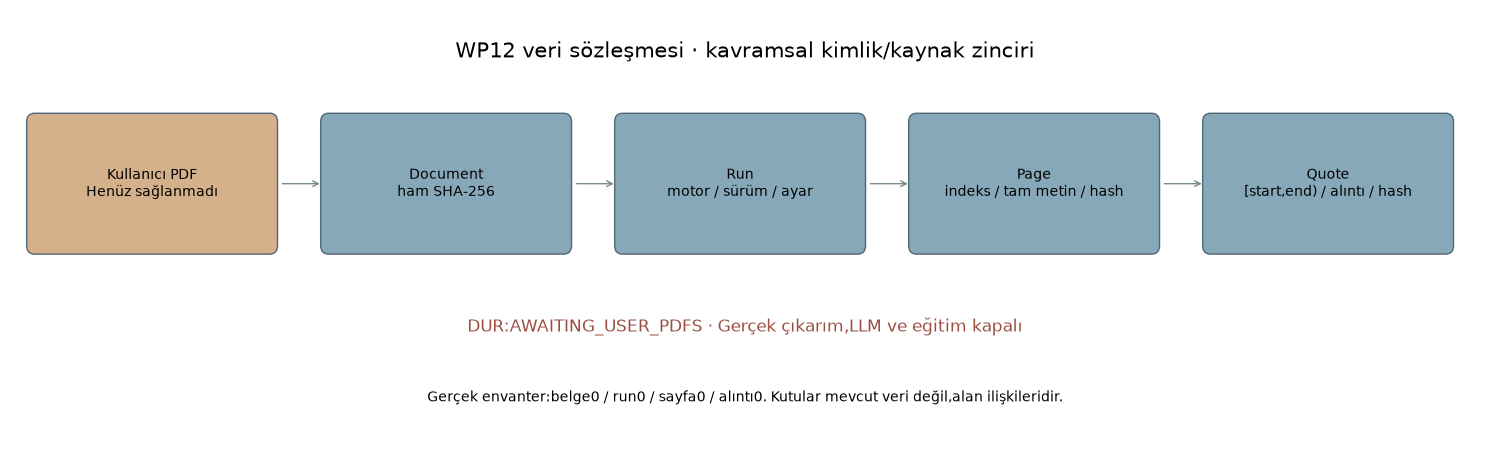

In [3]:

from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(15,4.6));ax.set(xlim=(0,15),ylim=(0,4));ax.axis('off')
boxes=[('Kullanıcı PDF\nHenüz sağlanmadı','#d4b18a'),('Document\nham SHA-256','#86a8b8'),('Run\nmotor / sürüm / ayar','#86a8b8'),('Page\nindeks / tam metin / hash','#86a8b8'),('Quote\n[start,end) / alıntı / hash','#86a8b8')]
for i,(label,color) in enumerate(boxes):
    x=.25+i*3
    ax.add_patch(FancyBboxPatch((x,1.8),2.4,1.15,boxstyle='round,pad=.08',facecolor=color,edgecolor='#526875'))
    ax.text(x+1.2,2.375,label,ha='center',va='center',fontsize=10)
    if i<4:ax.annotate('',xy=(x+2.94,2.375),xytext=(x+2.5,2.375),arrowprops={'arrowstyle':'->','color':'#7a8890'})
ax.text(7.5,3.55,'WP12 veri sözleşmesi · kavramsal kimlik/kaynak zinciri',ha='center',fontsize=15)
ax.text(7.5,1,'DUR:AWAITING_USER_PDFS · Gerçek çıkarım,LLM ve eğitim kapalı',ha='center',fontsize=12,color='#9b4d43')
ax.text(7.5,.35,'Gerçek envanter:belge0 / run0 / sayfa0 / alıntı0. Kutular mevcut veri değil,alan ilişkileridir.',ha='center',fontsize=10)
plt.tight_layout();plt.savefig(F/'01_document_provenance_contract.png',dpi=160);plt.show()


**Şema görselinin yorumu:**Bu beş kutu gerçek kayıt veya sonuç değildir. İleride kullanıcının dosyası ile sayfa/alıntı arasındaki provenans ilişkisini gösterir. Fiziksel sayfa indeksi0,insan numarası1 tabanlıdır;basılı etiket ayrı saklanır. Metin aralıkları Python Unicode kod noktalarında yarı açıktır;alıntı tam sayfa dizgesinin birebir dilimidir. Türkçe/emoji/satır sonu normalizasyonu sessizce yapılmaz.

## 3. Test edilen sözleşme ile henüz test edilmemiş belge işlemi

In [4]:

display(pd.read_csv(Q/'verification_scope.csv'))
print((Q/'contract_tests_v1.txt').read_text(encoding='utf-8'))


test_01_waiting_registry_really_empty (test_wp12_document_contract.DocumentContractTests.test_01_waiting_registry_really_empty) ... ok
test_02_fixture_cannot_enter_real_registry (test_wp12_document_contract.DocumentContractTests.test_02_fixture_cannot_enter_real_registry) ... ok
test_03_document_identity_is_exact_content_hash (test_wp12_document_contract.DocumentContractTests.test_03_document_identity_is_exact_content_hash) ... ok
test_04_duplicate_content_uses_receipt_aliases (test_wp12_document_contract.DocumentContractTests.test_04_duplicate_content_uses_receipt_aliases) ... ok
test_05_reject_automatic_source_and_URL (test_wp12_document_contract.DocumentContractTests.test_05_reject_automatic_source_and_URL) ... ok
test_06_original_filename_is_not_a_path (test_wp12_document_contract.DocumentContractTests.test_06_original_filename_is_not_a_path) ... ok
test_07_timezone_and_unique_receipt_required (test_wp12_document_contract.DocumentContractTests.test_07_timezone_and_unique_receipt_re

,control,status,scope
0,Belge/run/page/quote şeması,PASS_CONTRACT_TEST_ONLY,JSON yapısı ve yabancı anahtarlar
1,SHA ve deterministik kimlik,PASS_CONTRACT_TEST_ONLY,RAM teknik bayt/dizgeleri;gerçek PDF değil
2,Unicode aralık ve birebir alıntı,PASS_CONTRACT_TEST_ONLY,Türkçe/emoji/satır sonu teknik dizgeleri
3,Tekrar ve eksik/boş sayfa,PASS_CONTRACT_TEST_ONLY,Tamamlandı statüsü tüm fiziksel sayfaları gerektirir
4,Gerçek PDF kimliği/biçimi,NOT_RUN_NO_USER_PDF,Kullanıcı dosyası bekleniyor
5,PyMuPDF metin çıkarımı/okuma sırası,NOT_IMPLEMENTED,Parser bağlı değil
6,Tarama/OCR ihtiyacı,NOT_ASSESSED,Gerçek belge görülmedi
7,İlaç/tuz/formülasyon semantik eşleme,NOT_IMPLEMENTED,Dosya adından otomatik onay yok
8,Ollama/LLM,DISABLED,"Kurulum,indirme veya servis yok"
9,Yeni model eğitimi,DISABLED,Önceki sonuçlar sabit


**Yorum:**24 test yalnız RAM teknik fikstürlerini kullanır;prospektüs içeriği veya PDF dosyası değildir. `technical_test_fixture` üretim doğrulamasında reddedilir. Şema/ID/aralık/yabancı anahtar testleri geçti;gerçek PDF biçimi,sayfa okuma sırası,OCR,semantik eşleme veLLM davranışı doğrulanmış değildir. Çıkarım girişindeki hazırlık kapısı dosya açmadan durur.

## 4. Kaynak metin ile tahmini karıştırmamak

In [5]:

from wp12_prepare import preserve
print('Hash ile korunan önceki dosya:',preserve())
display(pd.DataFrame([{'kaynak':"verbatim_source_quote / reported_in_PDF",'model':"predicted_by_GNN / SHAP / Δz ayrı artefaktta",'anlam':"Kaynak alıntı klinik pozitif etiket veya bireysel risk değildir",'durum':"Kullanıcı PDF'leri bekleniyor"}]).T)


Hash ile korunan önceki dosya: 3183


,0
kaynak,verbatim_source_quote / reported_in_PDF
model,predicted_by_GNN / SHAP / Δz ayrı artefaktta
anlam,Kaynak alıntı klinik pozitif etiket veya bireysel risk değildir
durum,Kullanıcı PDF'leri bekleniyor


**Durma noktası:**Gerçek PDF sağlanınca salt okunur dosya/kimlik/biçim veçıkarım kontrolleri yapılacak. Şimdilik otomatik arama/indirme,gerçek çıkarım,LLM kurulumu/model indirmesi veya eğitim yoktur. Önceki WP00–WP11 dosyaları değişmedi. Sözleşme hazır;belge bekleniyor.